# 07 · Energy balances and adiabatic reactors

Heat is where reactor engineering earns its keep: an exothermic reaction heats itself, speeds up, and, if
nothing removes the heat, runs away; an endothermic one cools and stalls. This notebook adds the energy
balance to the mole balance, follows an adiabatic PFR along its temperature and conversion profile, meets
the equilibrium limit of an exothermic reversible reaction, and shows why the industrial answer is
interstage cooling.

**What you will learn**
- apply the adiabatic energy balance and the X-T line
- compute equilibrium conversion curves for exothermic reactions
- explain and simulate interstage cooling
- contrast exothermic and endothermic adiabatic operation

**Before you start:** notebooks 03 and 04  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import energy, kinetics, thermo
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The adiabatic energy balance

adiabatic temperature rise: 174 K - every 10 % of conversion adds 17.4 K
T0 = 290 K: outlet X = 0.128, T = 312.3 K
T0 = 300 K: outlet X = 1.000, T = 473.6 K
T0 = 310 K: outlet X = 1.000, T = 483.6 K


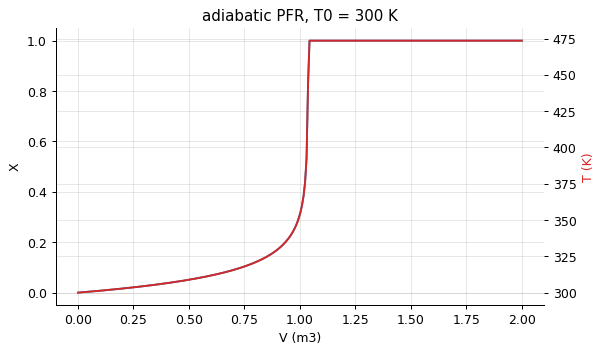

In [2]:
k0, Ea, dH = 5.0e7, 68e3, -250e3                                 # the course reaction A -> B
C_A0, cp_vol = 2500.0, 3.6e6                                    # mol/m3, J/(m3 K)
dT_ad = energy.adiabatic_temperature_rise(dH, C_A0, cp_vol)
print(f"adiabatic temperature rise: {dT_ad:.0f} K - every 10 % of conversion adds {dT_ad/10:.1f} K")
rate = lambda X, T: kinetics.arrhenius(k0, Ea, T) * C_A0 * (1 - X)
F_A0 = C_A0 * 1e-3                                              # 1 L/s feed
for T0 in (290.0, 300.0, 310.0):
    ad = energy.adiabatic_pfr(rate, F_A0, 2.0, T0, dH, sum_theta_cp=cp_vol / C_A0)
    print(f"T0 = {T0:.0f} K: outlet X = {ad['X'][-1]:.3f}, T = {ad['T'][-1]:.1f} K")
ad = energy.adiabatic_pfr(rate, F_A0, 2.0, 300.0, dH, sum_theta_cp=cp_vol / C_A0)
fig, ax = plt.subplots(); ax.plot(ad["V"], ad["X"], label="X"); ax2 = ax.twinx(); ax2.plot(ad["V"], ad["T"], "C3", label="T"); ax.set(xlabel="V (m3)", ylabel="X"); ax2.set_ylabel("T (K)", color="C3"); ax.set_title("adiabatic PFR, T0 = 300 K"); plt.show()

In an adiabatic reactor temperature and conversion are locked together, $T = T_0 + X\,\Delta T_{ad}$: the
energy balance is a straight line in the $X$-$T$ plane. A 10 K change in feed temperature moves the outlet
from about a tenth converted to complete - the exponential sensitivity that makes exothermic reactors both
efficient and hazardous. The profile shows an induction length where little happens, then a
front where everything does.

## Exothermic and reversible: the equilibrium ceiling

equilibrium SO2 conversion: 0.996 at 650 K, 0.904 at 800 K, 0.670 at 900 K


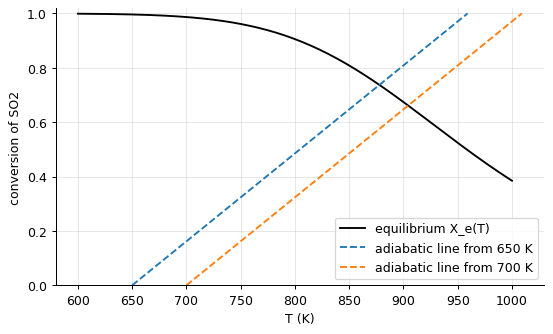

In [3]:
stoich = {"SO2": -1, "O2": -0.5, "SO3": 1}                            # SO2 oxidation, the contact process
T = np.linspace(600, 1000, 200)
K = np.array([thermo.equilibrium_constant(stoich, t) for t in T])
p = 1.0                                                                # bar; feed 10 % SO2, 11 % O2 (air), balance N2
def X_eq(Kp, T):
    from scipy import optimize
    f = lambda X: (0.1 * X / (1 - 0.05 * X)) / ((0.1 * (1 - X) / (1 - 0.05 * X)) * np.sqrt((0.11 - 0.05 * X) / (1 - 0.05 * X) * p)) - Kp
    return optimize.brentq(f, 1e-9, 1 - 1e-9)
Xe = np.array([X_eq(k_, t) for k_, t in zip(K, T)])
print(f"equilibrium SO2 conversion: {Xe[T >= 650][0]:.3f} at 650 K, {Xe[T >= 800][0]:.3f} at 800 K, {Xe[T >= 900][0]:.3f} at 900 K")
fig, ax = plt.subplots()
ax.plot(T, Xe, "k", label="equilibrium X_e(T)")
for T0 in (650.0, 700.0):
    dT = 0.1 * 98.9e3 / 32.0                                            # adiabatic rise per unit conversion for 10 % SO2 in a ~32 J/(mol K) gas... per mole of feed
    Xline = np.linspace(0, 1, 50)
    ax.plot(T0 + Xline * dT, Xline, "--", label=f"adiabatic line from {T0:.0f} K")
ax.set(xlabel="T (K)", ylabel="conversion of SO2", ylim=(0, 1.02)); ax.legend(); plt.show()

SO$_2$ oxidation is exothermic and reversible: the equilibrium conversion falls from near 1 at 650 K to
below 0.5 at 900 K, while the catalyst needs at least 700 K to work. An adiabatic bed climbs its straight
line until it hits the equilibrium curve - at perhaps 70 % - and stops. Hence the industrial design: four
adiabatic beds with cooling between them, each restarting at low temperature, staircasing up the
equilibrium curve to 99.7 %.

## Interstage cooling

In [4]:
k_cat = lambda T: kinetics.arrhenius(2.0e6, 80e3, T)                # a made-up catalyst: rate proportional to the distance from equilibrium
def bed(X_in, T_in, V):
    from scipy import integrate
    def rhs(v, s):
        X, T = s
        Kp = thermo.equilibrium_constant(stoich, T)
        Xe_ = X_eq(Kp, T)
        r = k_cat(T) * max(Xe_ - X, 0.0)                                # rate proportional to the distance from equilibrium
        return [r, r * dT]
    sol = integrate.solve_ivp(rhs, (0, V), [X_in, T_in], rtol=1e-8)
    return sol.y[0][-1], sol.y[1][-1]
X, T_ = 0.0, 690.0
for stage in range(1, 5):
    X, T_ = bed(X, T_, 1.0)
    print(f"bed {stage}: X = {X:.3f}, T = {T_:.0f} K -> cooled back to 690 K")
    T_ = 690.0

bed 1: X = 0.677, T = 899 K -> cooled back to 690 K
bed 2: X = 0.942, T = 772 K -> cooled back to 690 K
bed 3: X = 0.981, T = 702 K -> cooled back to 690 K
bed 4: X = 0.988, T = 692 K -> cooled back to 690 K


Each bed converts until it nears the equilibrium curve; cooling the gas back to the inlet temperature lets
the next bed continue. Four stages reach what one bed cannot at any temperature. The same logic - staged
adiabatic beds with interstage cooling, or cold-shot injection of fresh feed - runs ammonia synthesis,
methanol synthesis and the contact process.

## Endothermic reactions: the opposite problem

In [5]:
dH_endo = +80e3
rate_e = lambda X, T: kinetics.arrhenius(1e9, 90e3, T) * C_A0 * (1 - X)
for T0 in (600.0, 650.0, 700.0):
    ad_e = energy.adiabatic_pfr(rate_e, F_A0, 2.0, T0, dH_endo, sum_theta_cp=cp_vol / C_A0)
    print(f"endothermic, T0 = {T0:.0f} K: outlet X = {ad_e['X'][-1]:.3f}, T = {ad_e['T'][-1]:.0f} K (cooled by {T0 - ad_e['T'][-1]:.0f} K)")

endothermic, T0 = 600 K: outlet X = 1.000, T = 544 K (cooled by 56 K)
endothermic, T0 = 650 K: outlet X = 1.000, T = 594 K (cooled by 56 K)
endothermic, T0 = 700 K: outlet X = 1.000, T = 644 K (cooled by 56 K)


An endothermic reaction cools its own reactor and slows itself: adiabatic operation stalls, and the design
must supply heat - furnace tubes (steam cracking, reforming), or a fluidised bed with a hot solid circulating
in (catalytic cracking). Exothermic reactors fight to remove heat; endothermic ones fight to add it. Both
are energy-balance problems first.

## Inside the algorithm: the adiabatic line

In [6]:
X_ = 0.6
print("by hand: T =", 300.0 + X_ * dT_ad, "K; library profile at X = 0.6:", float(np.interp(X_, ad["X"], ad["T"])))

by hand: T = 404.1666666666667 K; library profile at X = 0.6: 404.1666666666667


## Exercises
1. Ammonia synthesis with a stoichiometric feed at 200 bar: compute the equilibrium conversion curve X_e(T) from `thermo` between 600 and 900 K, draw the adiabatic line from 650 K (Delta T_ad about 200 K per unit conversion), and read the maximum single-bed conversion. How many beds with cooling to 650 K reach 25 % conversion?
2. An endothermic first-order reaction (Ea = 90 kJ/mol, Delta H = +80 kJ/mol) is run in a PFR heated by a jacket at 750 K with Ua = 500 W/(m3 K). Using `energy.pfr_heat_exchange`, find the reactor volume for 80 % conversion and compare with the adiabatic case.
3. **Implement it yourself:** integrate the adiabatic PFR yourself with solve_ivp, substituting the energy balance for T(X) inside the rate, and reproduce `energy.adiabatic_pfr` for T0 = 300 K.